# Alibaba 2020 GPU Data
This file is based on [Alibaba's 2020 GPU data](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020). 
It is not in the git because of it's size (1.3GB compressed)


In [14]:
import pandas as pd
import numpy as np
import seaborn as sns

full_sensor_df = pd.read_csv('./data/alibaba-2020/pai_sensor_table.csv')
full_sensor_df.head()


,job_name,task_name,worker_name,inst_id,machine,gpu_name,cpu_usage,gpu_wrk_util,avg_mem,max_mem,avg_gpu_wrk_mem,max_gpu_wrk_mem,read,write,read_count,write_count
0,c6acdbd813439f3ca63a9406,worker,d50591d4a39b5a68e7efa15a0b51cfdca03e8f7a49ade7...,dc6e6daefec62bc3729def7e15133c03b82a97a1457d68...,4a57d4f3d41316da3c4ae876,/dev/nvidia5,0.603296,0.000000,0.232509,0.256836,0.000000,0.000000,4.666371e+03,6.608757e+03,50.706367,47.831054
1,c6acdbd813439f3ca63a9406,worker,fd1ee8bacf027604c2afdf89fc4edd843322b78376c9df...,dc6e6daefec62bc3729def7e15133c03b82a97a1457d68...,d84f5bc585e4ac5d24b30ec1,/dev/nvidia7,1.039332,0.000000,0.305684,0.343750,0.000000,0.000000,9.073576e+03,6.643213e+03,80.299497,47.311857
2,c6acdbd813439f3ca63a9406,worker,8885c53fd558926cb6aa44bbb7f40e242093778988c57d...,dc6e6daefec62bc3729def7e15133c03b82a97a1457d68...,b8dca09e0247ec64355414f9,/dev/nvidia2,0.287556,0.000000,0.345654,0.436523,0.000000,0.000000,4.852393e+03,6.681694e+03,50.627430,47.857114
3,3e4e9725920e7dc4a7a4ebdd,worker,8170c081a8d69cc228b9c2fa13a1c5e1190bf215296816...,ccc2b2c5742997e7ed0459efa6ec3db8b8e56e3f7fcd5f...,f7c1c4979c05bb7d20da65e4,/dev/nvidia7,83.771930,18.883333,5.817499,6.886719,2.065153,2.317383,1.504240e+08,5.082606e+07,7119.393443,75116.196721
4,3e4e9725920e7dc4a7a4ebdd,worker,e43f95191455f15365b40289c32b44648ce1e501331119...,ccc2b2c5742997e7ed0459efa6ec3db8b8e56e3f7fcd5f...,142a829a1e344f905fdcce42,/dev/nvidia2,112.711111,27.000000,5.494639,6.951172,2.001526,2.317383,1.854764e+08,6.311824e+07,9050.204082,93378.387755


In [3]:
SAMPLE_SIZE = 100_000

sensor_df = full_sensor_df.sample(SAMPLE_SIZE)

37.180812688172196

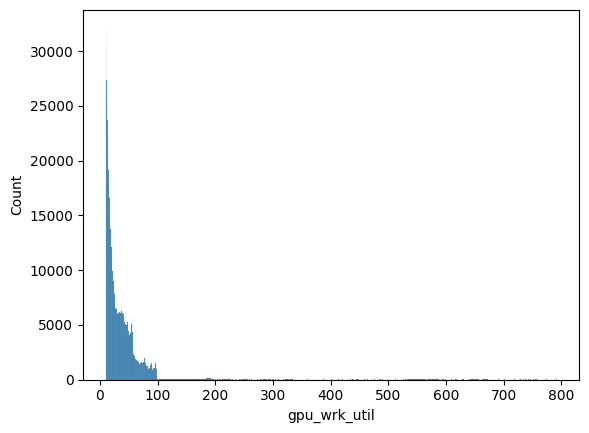

In [4]:
sensor_df_with_gpu = full_sensor_df[full_sensor_df["gpu_wrk_util"] >  10]
sns.histplot(sensor_df_with_gpu["gpu_wrk_util"])
sensor_df_with_gpu["gpu_wrk_util"].mean()

In [13]:
points = np.arange(0,800, 10)
count_dict: dict[int, int] = {}

last_point = 0
for point in points:
  count_dict[point] = 0
  current_count = len(full_sensor_df[full_sensor_df["gpu_wrk_util"] > float(point)])
  if last_point != 0:
    count_dict[last_point] -= current_count
  count_dict[point] = current_count
  last_point = point
  
count_dict_percents: dict[int, float] = {}
sensor_df_count = len(full_sensor_df)
sum = 0.0
for point, count in count_dict.items():
  count_dict_percents[point] = (float(count) / float(sensor_df_count)) * 100
  sum += count_dict_percents[point]

(count_dict_percents, sum)


({0: 65.45213158769259,
  10: 9.977871788244355,
  20: 4.018288083470041,
  30: 3.002309088127779,
  40: 2.5250294075758135,
  50: 1.9180860547429277,
  60: 0.8441820474002649,
  70: 0.7919605226372398,
  80: 0.5857118743307469,
  90: 0.47754342562652646,
  100: 0.013945520817398735,
  110: 0.012758667981875438,
  120: 0.012923508653475897,
  130: 0.012297114101394155,
  140: 0.014143329623319285,
  150: 0.01744014305532844,
  160: 0.018297314547650823,
  170: 0.023572216038865477,
  180: 0.05334244132990816,
  190: 0.027627296560236738,
  200: 0.00356055850656989,
  210: 0.005208965222574468,
  220: 0.005703487237375842,
  230: 0.003626494775210073,
  240: 0.0045166344018525454,
  250: 0.003164940894728791,
  260: 0.003164940894728791,
  270: 0.004252889327291813,
  280: 0.00461553880481282,
  290: 0.003626494775210073,
  300: 0.00356055850656989,
  310: 0.003395717834969432,
  320: 0.005571614700095475,
  330: 0.003000100223128333,
  340: 0.0014835660444041208,
  350: 0.0023077694024